# Projeto 01 - Teoria e Aplicação de Grafos

Este projeto analisa uma rede de amizades do Facebook. A partir de uma amostra de usuários, calculamos estatísticas do grafo, identificamos comunidades e comparamos medidas de centralidade.

## Etapas 1 e 2 - Carregamento dos dados e Seleção do subgrafo

O código baixa a lista de conexões da rede do Facebook, constrói o grafo completo e seleciona aleatoriamente 404 nós para formar o subgrafo de estudo.

A semente aleatória é definida a partir das matrículas dos integrantes para tornar a seleção reproduzível.

In [1]:
import networkx as nx
import pandas as pd
import random
import urllib

SEED = 231028746 + 251031785 + 242039579 # Soma das 3 matrículas para garantir uma seed
random.seed(SEED)

url="https://snap.stanford.edu/data/facebook_combined.txt.gz"
arquivo_local = "facebook_combined.txt.gz"
urllib.request.urlretrieve(url, arquivo_local)

G_full = nx.read_edgelist(arquivo_local, nodetype = int)
print(f"Estatísticas do Grafo Completo:")
print(f" - Total de nós: {G_full.number_of_nodes()}")
print(f" - Total de arestas: {G_full.number_of_edges()}")

nos_selecionados=random.sample(list(G_full.nodes()),404)
G_sub=G_full.subgraph(nos_selecionados).copy()

print(f"\nSubgrafo de estudo extraído:")
print(f" - Nós selecionados: {G_sub.number_of_nodes()}")
print(f" - Arestas preservadas: {G_sub.number_of_edges()}")

Estatísticas do Grafo Completo:
 - Total de nós: 4039
 - Total de arestas: 88234

Subgrafo de estudo extraído:
 - Nós selecionados: 404
 - Arestas preservadas: 810


## Etapa 3 - Comunidades e Centralidades

O algoritmo de Louvain identifica comunidades com base nas conexões entre os nós. Em seguida, são calculadas quatro medidas de centralidade para analisar diferentes aspectos da posição dos nós na rede.

In [2]:
comunidades = nx.community.louvain_communities(G_sub, seed = SEED)
print(comunidades)

centralidade = nx.degree_centrality(G_sub)
print(centralidade)

cent_intermediacao = nx.betweenness_centrality(G_sub)
print(cent_intermediacao)

cent_proximidade = nx.closeness_centrality(G_sub)
print(cent_proximidade)

cent_autovetor = nx.eigenvector_centrality(G_sub)
print(cent_autovetor)

[{2304, 2177, 2498, 2057, 2379, 2511, 2512, 2451, 2389, 2582, 2199, 1913, 2522, 2143, 2336, 1955, 1959, 2280, 2151, 2223, 2161, 2547, 2101, 2617, 1982}, {2079}, {2564, 2309, 2506, 2124, 2574, 2262, 2136, 2073, 2139, 2077, 2206, 2276, 2150, 2601, 2352, 2109, 2613, 2237, 2495}, {0, 1, 259, 134, 8, 9, 17, 274, 158, 30, 291, 298, 44, 178, 54, 183, 58, 62, 319, 64, 2885, 326, 74, 203, 78, 79, 80, 339, 84, 216, 223, 106, 121}, {2448, 2114, 2628, 2166, 2361, 2156, 2317}, {349}, {2017, 2421}, {379}, {383}, {401}, {2480}, {2281, 2487}, {441, 399}, {2145, 2514, 2066, 2453, 2406}, {2528}, {2569}, {530}, {541}, {546}, {2622, 2207}, {640, 578, 670, 583}, {2337, 2346, 2061, 1998, 1999, 2639, 2009, 1951}, {621}, {649}, {657}, {667}, {668}, {619, 685}, {689}, {2740}, {2767}, {3399, 2835, 2966, 3033, 3064, 3166, 2794, 2731, 2988, 3052, 3436, 2928, 3384, 2874, 3195, 3390, 3135}, {779}, {2851}, {818}, {705, 782, 849, 856, 729, 795, 738, 804, 813, 878, 820, 694, 695, 889, 762, 766}, {852}, {3131, 2902}, {

## Etapa 4 — Gráficos

### Estatísticas gerais

- **Número de vértices:** quantidade de nós no subgrafo.
- **Número de arestas:** quantidade de conexões entre os nós.
- **Grau médio dos vértices:** média de conexões por nó.
- **Densidade:** proporção das conexões possíveis que existem no subgrafo.
  - Compara as arestas existentes com o número máximo possível de arestas.

In [3]:
n = G_sub.number_of_nodes()
m = G_sub.number_of_edges()
grau_medio = sum(dict(G_sub.degree()).values()) / n
densidade = nx.density(G_sub)

estatisticas = pd.DataFrame({
    "Estatística": [ "Número de Vértices", "Número de Arestas", "Grau Médio", "Densidade" ],
    "Valor": [ n, m, round(grau_medio, 2), f"{densidade * 100:.3f}%"]
})

display(estatisticas)

,Estatística,Valor
0,Número de Vértices,404
1,Número de Arestas,810
2,Grau Médio,4.01
3,Densidade,0.995%


### Comunidades identificadas pelo algoritmo de Louvain

Uma **comunidade** é um grupo de nós com muitas conexões entre si em relação às conexões com o restante da rede. O gráfico usa cores para representar as comunidades identificadas.

Total de Comunidades: 105
Tamanhos das 10 Maiores Comunidades:
[47, 33, 28, 25, 24, 21, 19, 19, 17, 16]


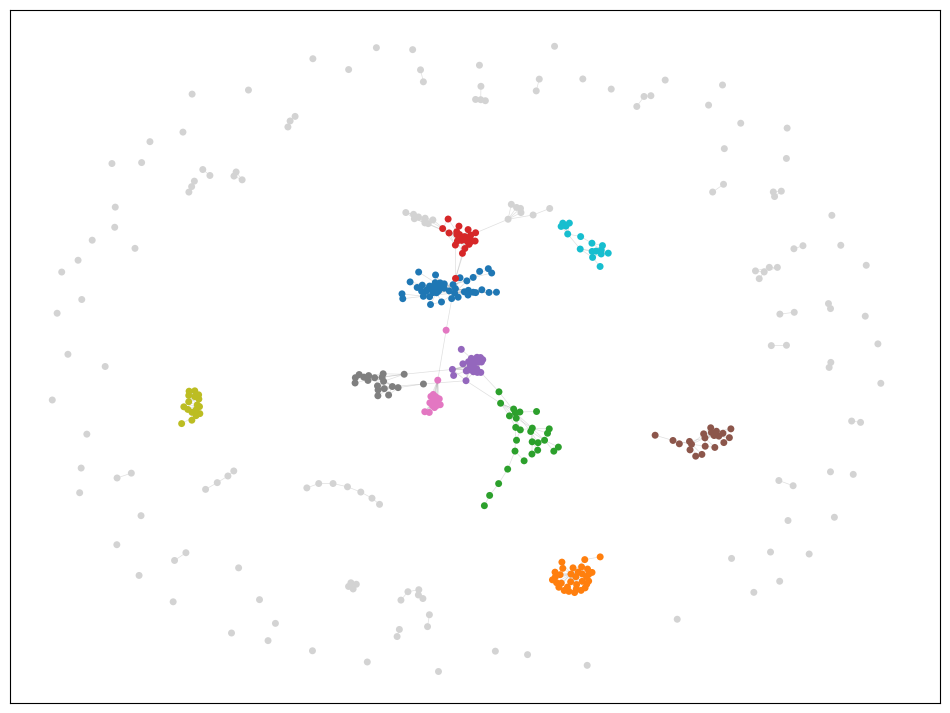

In [5]:
import matplotlib.pyplot as plt

# Ordena as comunidades da maior para a menor.
louvain = sorted(comunidades, key = len, reverse = True)

print(f"Total de Comunidades: {len(louvain)}")
print("Tamanhos das 10 Maiores Comunidades:")
print([len(c) for c in louvain[:10]])

# Calcula as posições dos nós para desenhar o grafo.
pos = nx.spring_layout(G_sub, seed = SEED)

cores_comunidades = plt.cm.tab10.colors
cor_por_no = {}

for i, comunidade in enumerate(louvain):
    # As 10 maiores recebem cores da paleta tab10; as demais ficam cinza.
    cor = cores_comunidades[i] if i < 10 else "lightgray"

    # Associa a cor da comunidade a cada um dos seus nós.
    for no in comunidade:
        cor_por_no[no] = cor

# Assocoa as cores na mesma ordem dos nós do grafo.
cores_nos = [cor_por_no[no] for no in G_sub.nodes()]

plt.figure(figsize = (12, 9))

# Desenha as Arestas.
nx.draw_networkx_edges(
    G_sub,
    pos,
    edge_color="gray",
    alpha=0.25,
    width=0.5
)

# Desenha os Vértices.
nx.draw_networkx_nodes(
    G_sub,
    pos,
    node_color=cores_nos,
    node_size=25,
    linewidths=0
)

plt.show()

### Medidas de Centralidade

As centralidades ajudam a comparar a posição dos nós na rede:

- **Grau:** considera a quantidade de conexões diretas de cada nó.
- **Intermediação:** considera quantas vezes um nó aparece nos caminhos mais curtos entre outros nós.
- **Proximidade:** considera a distância de um nó em relação aos demais.
- **Autovetor:** considera as conexões de um nó e também a importância dos nós aos quais ele está conectado.

As tabelas apresentam os dez maiores valores de cada medida. Nos gráficos, o tamanho e a cor dos nós representam seus valores de centralidade, e os cinco maiores são identificados com rótulos.


Dez Maiores Valores - Centralidade de Grau


,Nó,Valor
0,0,0.07692
1,2199,0.04715
2,3291,0.04467
3,2206,0.04218
4,1199,0.04218
5,3320,0.04218
6,2336,0.03970
7,2951,0.03970
8,2139,0.03722
9,2223,0.03722


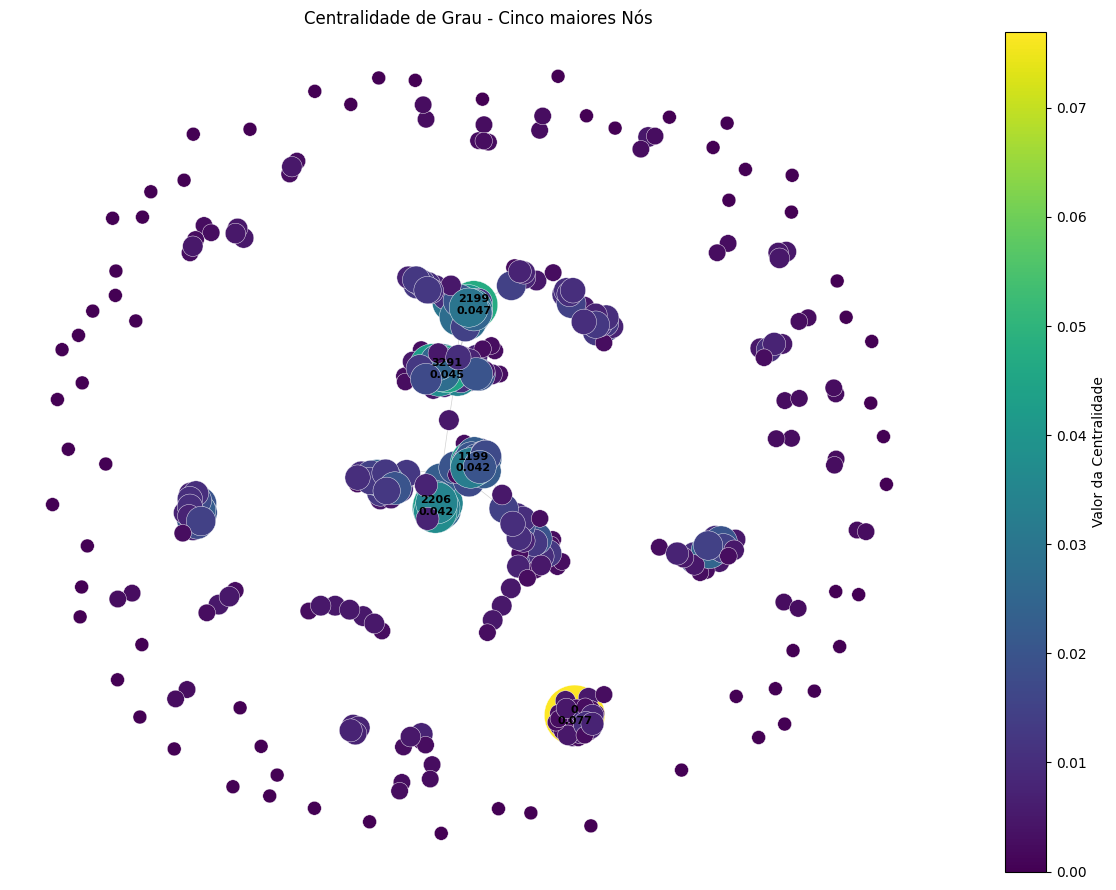


Dez Maiores Valores - Centralidade de Intermediação


,Nó,Valor
0,934,0.01325
1,1155,0.01141
2,1982,0.00916
3,2262,0.00889
4,2506,0.00861
5,921,0.00671
6,366,0.00605
7,1404,0.00601
8,0,0.00583
9,2512,0.00553


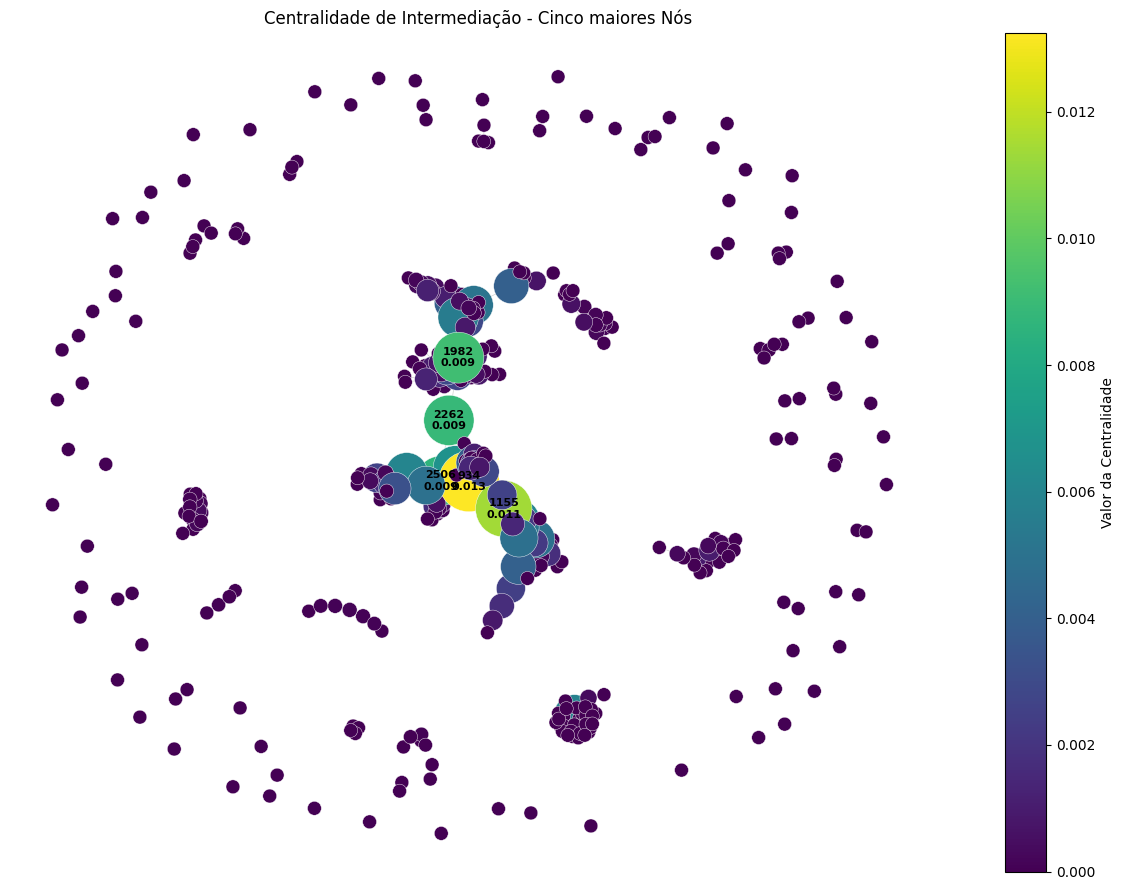


Dez Maiores Valores - Centralidade de Proximidade


,Nó,Valor
0,0,0.07700
1,3291,0.06563
2,3002,0.06326
3,2951,0.06251
4,3198,0.06035
5,934,0.05790
6,3038,0.05770
7,3345,0.05707
8,3113,0.05646
9,3360,0.05586


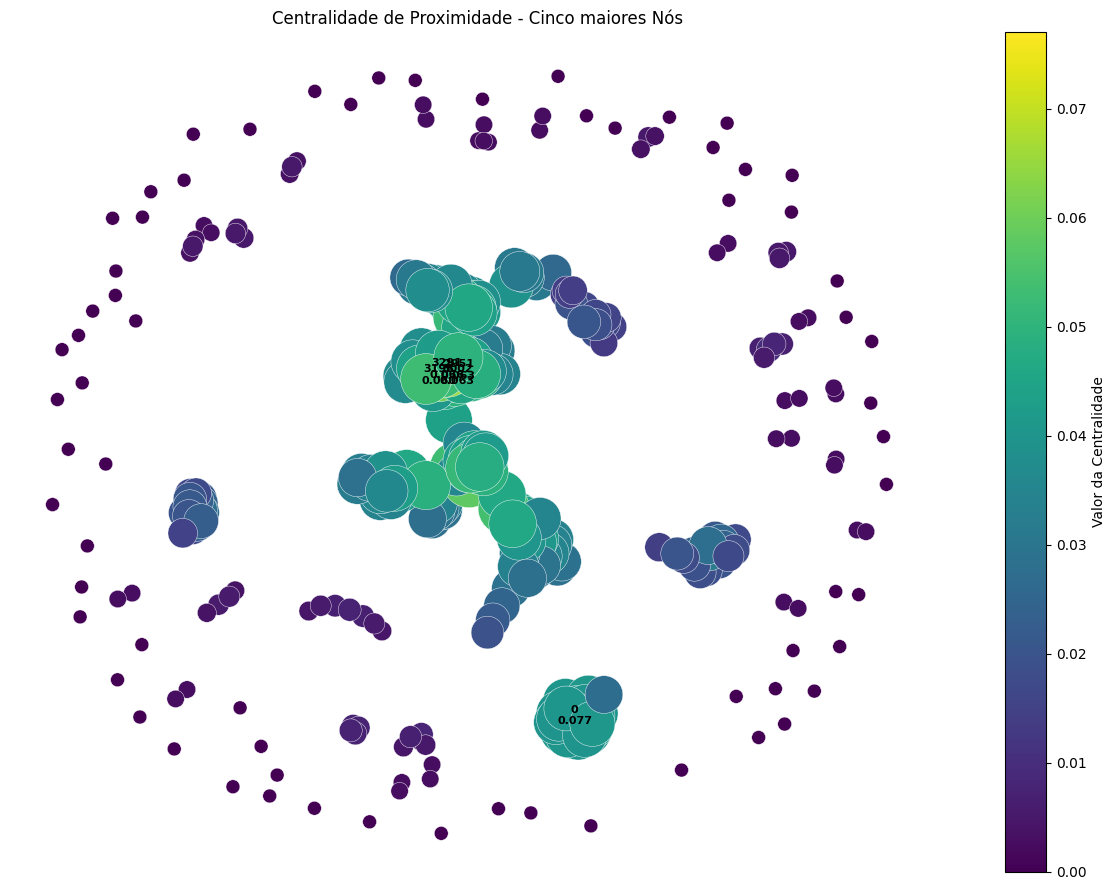


Dez Maiores Valores - Centralidade de Autovetor


,Nó,Valor
0,2206,0.29483
1,2309,0.28430
2,2139,0.27741
3,2073,0.27150
4,2601,0.27150
5,2564,0.27039
6,2276,0.26874
7,2352,0.26866
8,2495,0.25497
9,2124,0.24475


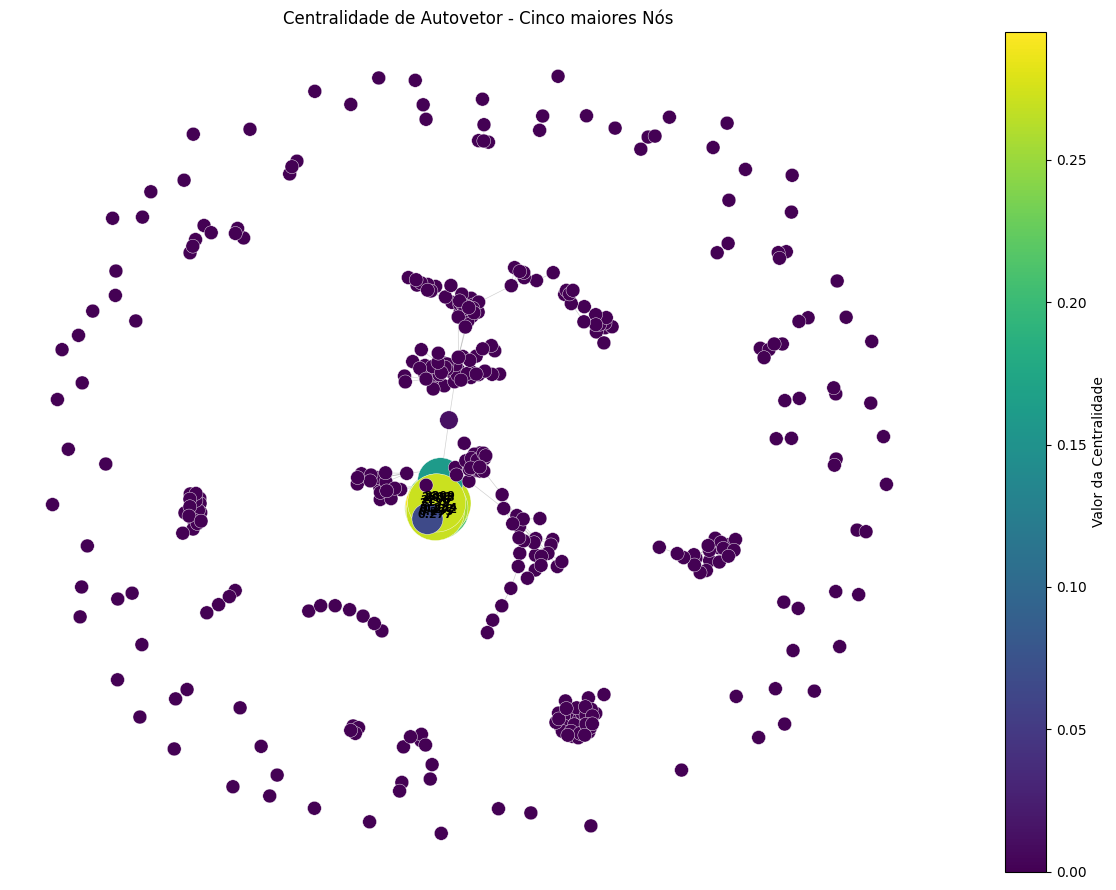

In [6]:
medidas = {
    "Grau": centralidade,
    "Intermediação": cent_intermediacao,
    "Proximidade": cent_proximidade,
    "Autovetor": cent_autovetor,
}

# Calcula as posições dos nós para desenhar o grafo.
pos = nx.spring_layout(G_sub, seed=SEED)

# Percorre cada medida de centralidade e seus valores por nó.
for nome, valores in medidas.items():

    # Seleciona os 10 nós com os maiores valores de centralidade.
    top10 = sorted(
        valores.items(),
        key = lambda item: item[1],
        reverse = True
    )[:10]

    tabela = pd.DataFrame(top10, columns=["Nó", "Valor"])
    print(f"\nDez Maiores Valores - Centralidade de {nome}")
    display(tabela.style.format({"Valor": "{:.5f}"}))

    # Define o tamanho dos nós proporcionalmente à centralidade.
    maior = max(valores.values())
    tamanhos = [100 + 1800 * valores[no] / maior for no in G_sub.nodes()]

    # Prepara a identificação dos cinco nós com maior centralidade.
    top5 = [no for no, _ in top10[:5]]
    rotulos = {no: f"{no}\n{valores[no]:.3f}" for no in top5}

    plt.figure(figsize=(12, 9))

    # Desenha as Arestas
    nx.draw_networkx_edges(G_sub, pos, alpha=0.18, width=0.5)

    # Desenha os Vértices; tamanho e cor representam a centralidade.
    nos = nx.draw_networkx_nodes(
        G_sub, pos,
        node_size = tamanhos,
        node_color = [valores[no] for no in G_sub.nodes()],
        cmap = plt.cm.viridis,
        edgecolors = "white",
        linewidths = 0.3,
    )

    # Exibe o identificador e o valor dos cinco nós mais centrais.
    nx.draw_networkx_labels( G_sub, pos, labels = rotulos, font_size = 8, font_weight = "bold")

    plt.title(f"Centralidade de {nome} - Cinco maiores Nós")
    plt.colorbar(nos, label="Valor da Centralidade")
    plt.axis("off")
    plt.tight_layout()

    plt.show()